# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 00: Chronological Train / Test Split
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All code blocks below are labeled as AI-assisted. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below.

---

This is the only notebook that reads the raw dataset (`data/hour.csv`). It splits the data once and writes:
- `data/train_clean.csv`: training set, read by Notebooks 01–05.
- `data/test_locked.csv`: locked test set, read once in Notebook 06.

The data quality audit is carried out on the training set in Notebook 01.

## 1. Setup and Raw Data Loading
*Code: Generated by AI Assistant*

In [1]:
import os
import sys

# Ensure local source modules can be imported
sys.path.append(os.path.abspath('..'))
from src.data_utils import load_raw, chronological_split, save_split, SPLIT_DATE

df_raw = load_raw()
print(f"Raw dataset loaded. Shape: {df_raw.shape}")

Raw dataset loaded. Shape: (17379, 17)


## 2. Chronological Train / Test Split & Test Set Lock (Workflow Step 1)
*Code: Generated by AI Assistant*

Adjacent hours exhibit severe autocorrelation ($\rho_1 \approx 0.88, \rho_{24} \approx 0.70$). A random split would place neighboring hours in both train and test, producing optimistically leaking test errors.
- **Split Date**: `2012-10-01`
- **Training Set**: 2011-01-01 to 2012-09-30 ($N = 15,211$, 87.5%)
- **Holdout Test Set**: 2012-10-01 to 2012-12-31 ($N = 2,168$, 12.5%)
- The holdout test set is locked into `data/test_locked.csv` and not called until Notebook 06.


In [2]:
# Execute chronological split (split date defined once in src.data_utils)
train_df, test_df = chronological_split(df_raw, SPLIT_DATE)
assert train_df['dteday'].max() < test_df['dteday'].min()
assert len(train_df) + len(test_df) == len(df_raw)

print(f"Training set: {len(train_df):,} rows ({len(train_df)/len(df_raw)*100:.1f}%) | Range: {train_df['dteday'].min().date()} to {train_df['dteday'].max().date()}")
print(f"Holdout test: {len(test_df):,} rows ({len(test_df)/len(df_raw)*100:.1f}%) | Range: {test_df['dteday'].min().date()} to {test_df['dteday'].max().date()}")

# Save split sets to disk
train_path, test_path = save_split(train_df, test_df)
print(f"Saved training set to: {train_path}")
print(f"Saved locked test set to: {test_path} (Locked away for Notebook 06 audit)")

Training set: 15,211 rows (87.5%) | Range: 2011-01-01 to 2012-09-30
Holdout test: 2,168 rows (12.5%) | Range: 2012-10-01 to 2012-12-31
Saved training set to: Z:\DSA211\data\train_clean.csv
Saved locked test set to: Z:\DSA211\data\test_locked.csv (Locked away for Notebook 06 audit)


### Train / Test Split Visual
*Code: Generated by AI Assistant*

Daily total rentals with the chronological split marked. Uses the in-memory split only; the locked test file is not read.

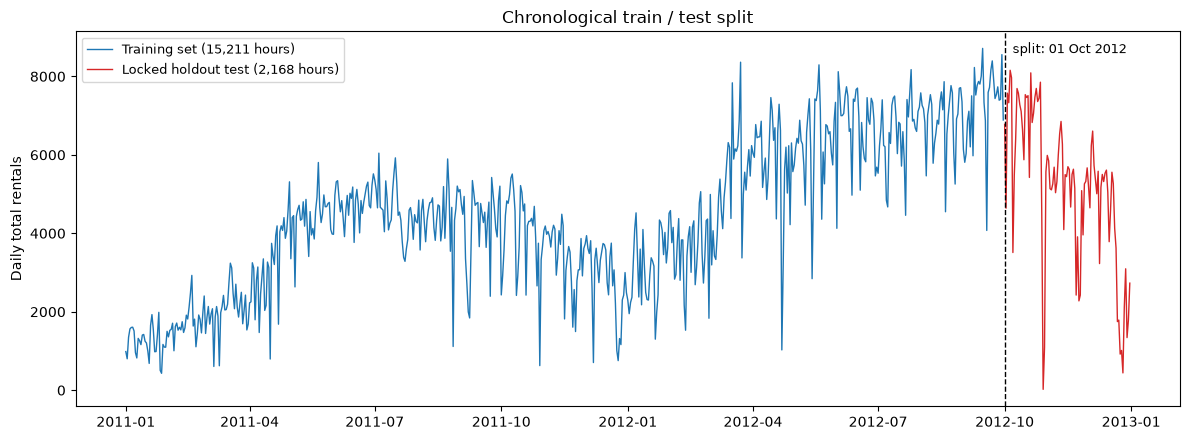

In [3]:
import matplotlib.pyplot as plt

daily_train = train_df.groupby('dteday')['cnt'].sum()
daily_test = test_df.groupby('dteday')['cnt'].sum()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily_train.index, daily_train.values, color='tab:blue', lw=1, label=f'Training set ({len(train_df):,} hours)')
ax.plot(daily_test.index, daily_test.values, color='tab:red', lw=1, label=f'Locked holdout test ({len(test_df):,} hours)')
ax.axvline(SPLIT_DATE, color='k', ls='--', lw=1)
ax.text(SPLIT_DATE, ax.get_ylim()[1] * 0.97, f'  split: {SPLIT_DATE:%d %b %Y}', va='top', fontsize=9)
ax.set_ylabel('Daily total rentals')
ax.set_title('Chronological train / test split')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join('..', 'figures', '07_train_test_split.png'), dpi=150)
plt.show()

### Split Justification & Decisions
**Author**: Lee Sin Yang
<!-- Add your reasoning for using a chronological holdout over random splitting and how it addresses temporal autocorrelation here -->
For time series datasets, rows between each data point (e.g. hour 1 and hour 2) are highly autocorrelated. We thus hold out a final holdout block rather than random rows to properly evaluate if our model is able to predict without relying on just the rows before and after.

The test set is 12.5% of rows, data from 2012-10-01 to 2012-12-31. This will be the true test of the final model, and will only be scored once.